# Datenexploration

## Init

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = '../../data/raw/sickness_table.csv'

df = pd.read_csv(file_path, index_col=0)

# Explorative Datenanalyse (EDA)

In [2]:
# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Dateninspektion
display(df.info())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
Index: 1152 entries, 0 to 1151
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      1152 non-null   datetime64[ns]
 1   n_sick    1152 non-null   int64         
 2   calls     1152 non-null   float64       
 3   n_duty    1152 non-null   int64         
 4   n_sby     1152 non-null   int64         
 5   sby_need  1152 non-null   float64       
 6   dafted    1152 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(3)
memory usage: 72.0 KB


None

,date,n_sick,calls,n_duty,n_sby,sby_need,dafted
count,1152,1152.000000,1152.000000,1152.000000,1152.0,1152.000000,1152.000000
mean,2017-10-28 12:00:00,68.808160,7919.531250,1820.572917,90.0,34.718750,16.335938
min,2016-04-01 00:00:00,36.000000,4074.000000,1700.000000,90.0,0.000000,0.000000
25%,2017-01-13 18:00:00,58.000000,6978.000000,1800.000000,90.0,0.000000,0.000000
50%,2017-10-28 12:00:00,68.000000,7932.000000,1800.000000,90.0,0.000000,0.000000
75%,2018-08-12 06:00:00,78.000000,8827.500000,1900.000000,90.0,12.250000,0.000000
max,2019-05-27 00:00:00,119.000000,11850.000000,1900.000000,90.0,555.000000,465.000000
std,NaN,14.293942,1290.063571,80.086953,0.0,79.694251,53.394089


In [3]:
display(df)

,date,n_sick,calls,n_duty,n_sby,sby_need,dafted
0,2016-04-01,73,8154.0,1700,90,4.0,0.0
1,2016-04-02,64,8526.0,1700,90,70.0,0.0
2,2016-04-03,68,8088.0,1700,90,0.0,0.0
3,2016-04-04,71,7044.0,1700,90,0.0,0.0
4,2016-04-05,63,7236.0,1700,90,0.0,0.0
...,...,...,...,...,...,...,...
1147,2019-05-23,86,8544.0,1900,90,0.0,0.0
1148,2019-05-24,81,8814.0,1900,90,0.0,0.0
1149,2019-05-25,76,9846.0,1900,90,146.0,56.0
1150,2019-05-26,83,9882.0,1900,90,160.0,70.0


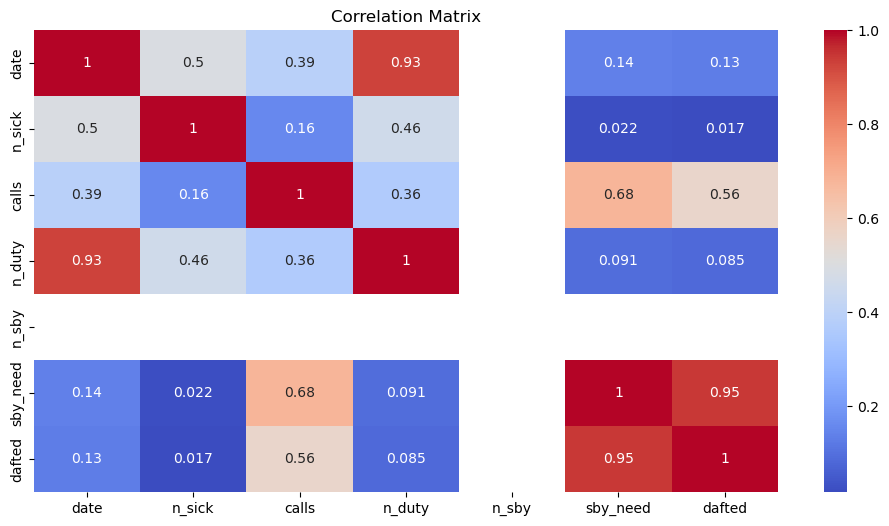

In [4]:
# Visualisierungen
#plt.figure(figsize=(12, 6))
#sns.histplot(df['n_sick'], kde=True)
#plt.title('Distribution of n_sick')
#plt.show()

#plt.figure(figsize=(12, 6))
#sns.histplot(df['calls'], kde=True)
#plt.title('Distribution of calls')
#plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

#To-Do: Visualiserung und Verteilung der Anrufe ist evtl. nicht ideal

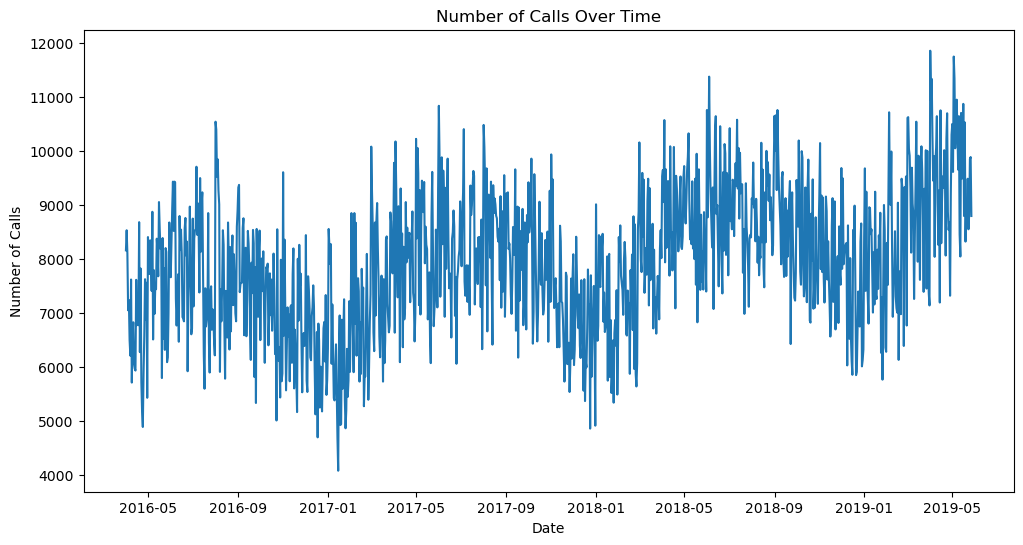

In [5]:
# Plot n_sick over time
#plt.figure(figsize=(12, 6))
#sns.lineplot(data=df, x='date', y='n_sick')
#plt.title('Number of Sick Employees Over Time')
#plt.xlabel('Date')
#plt.ylabel('Number of Sick Employees')
#plt.show()

# Plot calls over time
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='date', y='calls')
plt.title('Number of Calls Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Calls')
plt.show()

# Datenvorbereitung

In [6]:
working_df = df.copy(deep=True)

print("Number NaN values:", working_df.isna().sum())

# Umgang mit fehlenden Werten
working_df = working_df.dropna()

Number NaN values: date        0
n_sick      0
calls       0
n_duty      0
n_sby       0
sby_need    0
dafted      0
dtype: int64


In [7]:
import requests

# Jahr und Bundesland definieren
year = 2024
state = 'BE'  # Notfalldienst aus Berlin

# API-URL
url = f'https://feiertage-api.de/api/?jahr={year}&nur_land={state}'

response = requests.get(url)
holidays = response.json()

holiday_dates = [pd.to_datetime(info['datum']) for name, info in holidays.items()]

working_df['is_holiday'] = working_df['date'].isin(holiday_dates).astype(bool)

In [8]:
# Feature Engineering
working_df['year'] = working_df['date'].dt.year
working_df['month'] = working_df['date'].dt.month
working_df['day_of_week'] = working_df['date'].dt.dayofweek
working_df['day_of_month'] = working_df['date'].dt.day
working_df['week_of_year'] = working_df['date'].dt.isocalendar().week
working_df['day_of_year'] = working_df['date'].dt.dayofyear
working_df['is_weekend'] = working_df['day_of_week'] >= 5

working_df['unix_ts_date'] = working_df['date'].astype(int) // 10**9 # noch nicht ganz sicher, ob das exakt passt


working_df["needed_personal"] = working_df.apply(lambda row: (row.sby_need + row.n_duty - row.n_sick), axis=1)
working_df["calls_per_duty"] = working_df.apply(lambda row: row.calls / row.n_duty, axis=1)
working_df["call_stress"] = working_df.apply(lambda row: row.calls / (row.n_duty + row.sby_need), axis=1)
working_df["sby_used_percent"] = working_df.apply(lambda row: (row.sby_need / row.n_sby) * 100, axis=1)

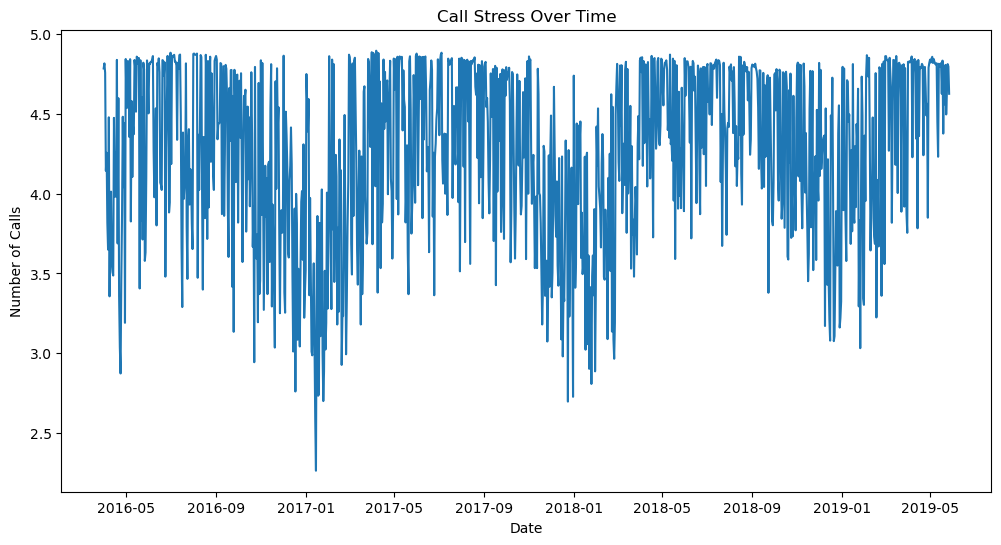

In [9]:
# Plot calls over time
plt.figure(figsize=(12, 6))
sns.lineplot(data=working_df, x='date', y='call_stress')
plt.title('Call Stress Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Calls')
plt.show()


# mit max 5 Calls pro verfügbare Person sollte es auskommen.
# Ziel:  Calls besser hervorsagen

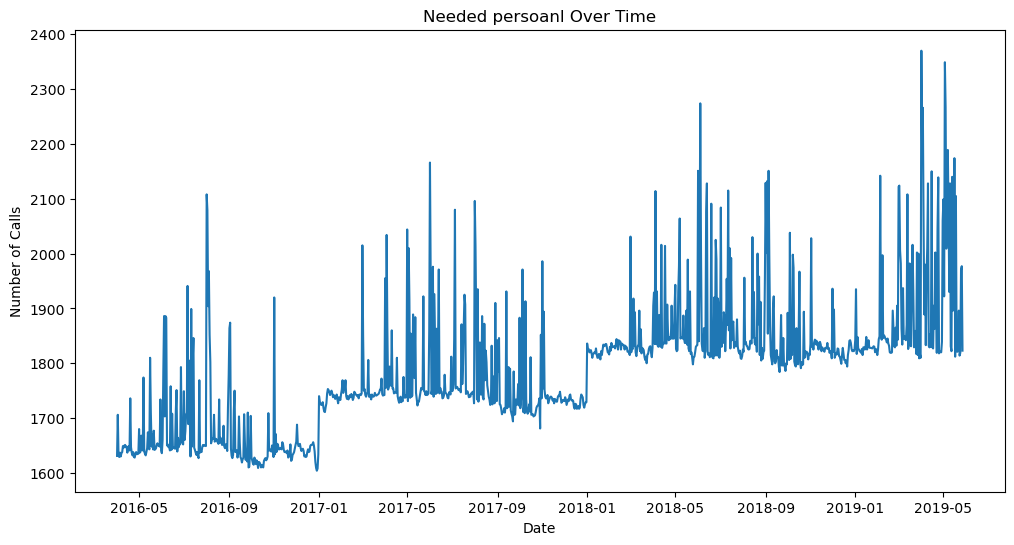

In [11]:
# Plot calls over time
plt.figure(figsize=(12, 6))
sns.lineplot(data=working_df, x='date', y='needed_personal')
plt.title('Needed persoanl Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Calls')
plt.show()


In [12]:
import warnings

if False:

    warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)

    feature_list = ["calls", "n_sick", "sby_need", "calls_per_duty", "call_stress", "n_duty", "dafted"]

    for feature in feature_list:
        for i in range(0, 4):
            number_of_days = 2 ** i

            #print(f"{number_of_days =}")

            # Gleitende Durchschnitte erstellen
            working_df[f'{feature}_ma_{number_of_days}'] = working_df[feature].rolling(window=number_of_days).mean()
            # Gleitende Mediane erstellen
            working_df[f'{feature}_median_{number_of_days}'] = working_df[feature].rolling(window=number_of_days).median()
            # Gleitende Standardabweichungen erstellen
            working_df[f'{feature}_std_{number_of_days}'] = working_df[feature].rolling(window=number_of_days).std()

            # Lag-Features erstellen (14 Tage Schritte)
            for k in range(0, 3):  # Beispielhaft 14 Tage und 28 Tage Lag-Features
                days_in_past = 2 ** k
                print(f"{days_in_past =}")

                working_df[f'{feature}_ma_{number_of_days}_lag_{days_in_past}'] = working_df[f'{feature}_ma_{number_of_days}'].shift(days_in_past)
                working_df[f'{feature}_median_{number_of_days}_lag_{days_in_past}'] = working_df[f'{feature}_median_{number_of_days}'].shift(days_in_past)
                working_df[f'{feature}_std_{number_of_days}_lag_{days_in_past}'] = working_df[f'{feature}_std_{number_of_days}'].shift(days_in_past)

            # Drop after creating lag features
            working_df.drop(columns=[f'{feature}_ma_{number_of_days}'], inplace=True)
            working_df.drop(columns=[f'{feature}_median_{number_of_days}'], inplace=True)
            working_df.drop(columns=[f'{feature}_std_{number_of_days}'], inplace=True)

        # Entstandene NaN durch Median ersetzen (um Robustheit gegenüber Ausreißern zu gewährleisten)
        working_df = working_df.ffill().bfill()

In [13]:
def get_season(month):
    if month in [12, 1, 2]:
        return 0 #Winter
    elif month in [3, 4, 5]:
        return 1 #Frühling
    elif month in [6, 7, 8]:
        return 2 # Sommer
    else:
        return 3 # Herbst

working_df['season'] = working_df['month'].apply(get_season)

In [14]:
pd.set_option('float_format', '{:f}'.format)
print("New dataframe:")
display(working_df)
display(working_df.describe())


display(working_df.columns)

New dataframe:


,date,n_sick,calls,n_duty,n_sby,sby_need,dafted,is_holiday,year,month,...,day_of_month,week_of_year,day_of_year,is_weekend,unix_ts_date,needed_personal,calls_per_duty,call_stress,sby_used_percent,season
0,2016-04-01,73,8154.000000,1700,90,4.000000,0.000000,False,2016,4,...,1,13,92,False,1459468800,1631.000000,4.796471,4.785211,4.444444,1
1,2016-04-02,64,8526.000000,1700,90,70.000000,0.000000,False,2016,4,...,2,13,93,True,1459555200,1706.000000,5.015294,4.816949,77.777778,1
2,2016-04-03,68,8088.000000,1700,90,0.000000,0.000000,False,2016,4,...,3,13,94,True,1459641600,1632.000000,4.757647,4.757647,0.000000,1
3,2016-04-04,71,7044.000000,1700,90,0.000000,0.000000,False,2016,4,...,4,14,95,False,1459728000,1629.000000,4.143529,4.143529,0.000000,1
4,2016-04-05,63,7236.000000,1700,90,0.000000,0.000000,False,2016,4,...,5,14,96,False,1459814400,1637.000000,4.256471,4.256471,0.000000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1147,2019-05-23,86,8544.000000,1900,90,0.000000,0.000000,False,2019,5,...,23,21,143,False,1558569600,1814.000000,4.496842,4.496842,0.000000,1
1148,2019-05-24,81,8814.000000,1900,90,0.000000,0.000000,False,2019,5,...,24,21,144,False,1558656000,1819.000000,4.638947,4.638947,0.000000,1
1149,2019-05-25,76,9846.000000,1900,90,146.000000,56.000000,False,2019,5,...,25,21,145,True,1558742400,1970.000000,5.182105,4.812317,162.222222,1
1150,2019-05-26,83,9882.000000,1900,90,160.000000,70.000000,False,2019,5,...,26,21,146,True,1558828800,1977.000000,5.201053,4.797087,177.777778,1


,date,n_sick,calls,n_duty,n_sby,sby_need,dafted,year,month,day_of_week,day_of_month,week_of_year,day_of_year,unix_ts_date,needed_personal,calls_per_duty,call_stress,sby_used_percent,season
count,1152,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000
mean,2017-10-28 12:00:00,68.808160,7919.531250,1820.572917,90.000000,34.718750,16.335938,2017.333333,6.424479,3.002604,15.674479,26.023438,180.072049,1509192000.000000,1786.483507,4.347109,4.255659,38.576389,1.479167
min,2016-04-01 00:00:00,36.000000,4074.000000,1700.000000,90.000000,0.000000,0.000000,2016.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1459468800.000000,1604.000000,2.263333,2.263333,0.000000,0.000000
25%,2017-01-13 18:00:00,58.000000,6978.000000,1800.000000,90.000000,0.000000,0.000000,2017.000000,4.000000,1.000000,8.000000,14.000000,95.000000,1484330400.000000,1721.750000,3.875833,3.875833,0.000000,1.000000
50%,2017-10-28 12:00:00,68.000000,7932.000000,1800.000000,90.000000,0.000000,0.000000,2017.000000,6.000000,3.000000,16.000000,25.000000,174.000000,1509192000.000000,1796.000000,4.344298,4.344298,0.000000,1.000000
75%,2018-08-12 06:00:00,78.000000,8827.500000,1900.000000,90.000000,12.250000,0.000000,2018.000000,9.000000,5.000000,23.000000,39.000000,270.000000,1534053600.000000,1834.000000,4.831625,4.778991,13.611111,2.000000
max,2019-05-27 00:00:00,119.000000,11850.000000,1900.000000,90.000000,555.000000,465.000000,2019.000000,12.000000,6.000000,31.000000,52.000000,366.000000,1558915200.000000,2370.000000,6.236842,4.896288,616.666667,3.000000
std,NaN,14.293942,1290.063571,80.086953,0.000000,79.694251,53.394089,0.977594,3.394101,2.002386,8.778030,14.770423,103.880984,28745112.497258,114.121491,0.663532,0.539535,88.549168,1.092387


Index(['date', 'n_sick', 'calls', 'n_duty', 'n_sby', 'sby_need', 'dafted',
       'is_holiday', 'year', 'month', 'day_of_week', 'day_of_month',
       'week_of_year', 'day_of_year', 'is_weekend', 'unix_ts_date',
       'needed_personal', 'calls_per_duty', 'call_stress', 'sby_used_percent',
       'season'],
      dtype='object')

# Datenexport

In [15]:
working_df.to_csv("../../data/processed/sickness_table.csv")

## Kleine Modelle für Feature Importance etc

In [21]:
# Datenaufteilung
from sklearn.model_selection import train_test_split


target_column_name = "calls"

# Datum u. U. auch eibinden. Muss dann aber konvertiert werden

#X = working_df[['unix_ts_date', 'calls', 'n_duty', 'n_sby', 'n_sick', 'month', 'day_of_week', 'call_stress', 'calls_per_duty', 'is_holiday', 'is_weekend']] #dafted für Training weglassen, da dies direkt Aufschluss darüber gibt, dass der Wert über 100 liegt


#X = working_df[[ 'month', 'season', 'day_of_week', 'is_holiday', 'is_weekend']] #nur auf zeitliche Faktoren beschränkt

#X = working_df.loc[:, working_df.columns != target_column_name]
#X.drop(columns=['date', "sby_need", "dafted", "calls_per_duty", "calls", "call_stress", "n_sick"], inplace=True)

excluded_columns = ["sby_need", "dafted", "n_sick", "calls", "call_stress", "sby_used_percent", "calls_per_duty", "date", "unix_ts_date", "needed_personal"]

usable_columns = list(set(working_df.columns) - set(excluded_columns))

X = working_df[usable_columns]


# Annahme: n_sby soll vorhergesagt werden, aber da es in der Historie fest den Wert 90 hat, kann man darauf nicht direkt predicten
# Ziel: sby_used_percent soll nahezu 100% betragen, aber nicht darüber liegen. To-Do: n_sby ausrechnen. 
# Idee: Eingabe an API mit Werten rein. Programm sagt, Warnung, die Kapazitäten werden voraussichtlich nur zu X Prozent genutzt und entsprechend wird bei n_sby dann reduziert. Im Umkehrfall bei über 100% wird erhöht
y = working_df[target_column_name]  

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

## Baseline-Modell

Baseline MAE: 0.0


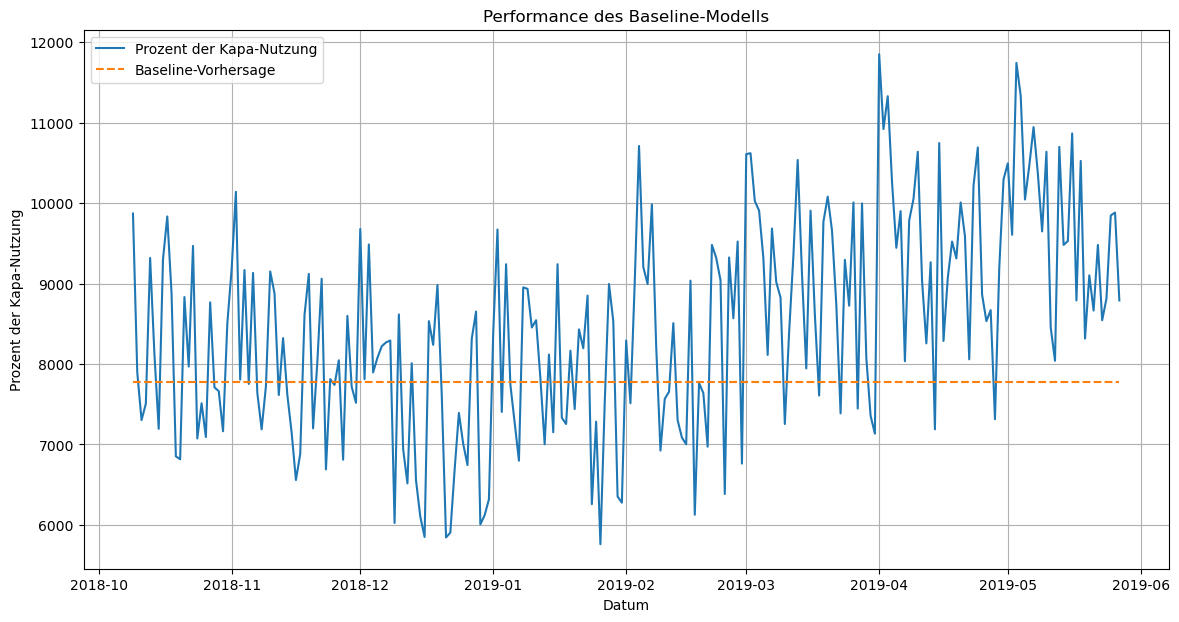

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

train_size = int(len(working_df) * 0.8)
train, test = working_df.iloc[:train_size], working_df.iloc[train_size:]

# Baseline-Modell: Durchschnitt der Zielvariable im Trainingsset
mean_calls_train = train['calls'].mean()

test = test.copy() # Zum Verhindern der SettingWithCopyWarning
# Vorhersagen für das Testset mit dem Baseline-Modell
test['baseline_pred'] = mean_calls_train

# Berechnung des Mean Absolute Error (MAE) für das Baseline-Modell
mae_baseline = mean_absolute_error(test['calls'], test['calls'])
print(f'Baseline MAE: {mae_baseline}')

# Visualisierung der Performance des Baseline-Modells
plt.figure(figsize=(14, 7))
plt.plot(test['date'], test['calls'], label='Prozent der Kapa-Nutzung')
plt.plot(test['date'], test['baseline_pred'], label='Baseline-Vorhersage', linestyle='--')
plt.xlabel('Datum')
plt.ylabel('Prozent der Kapa-Nutzung')
plt.title('Performance des Baseline-Modells')
plt.legend()
plt.grid(True)
plt.show()

## Erstellung und Evaluation des Vorhersagemodells

In [23]:
# Auswahl und Training eines Modells
from sklearn.ensemble import RandomForestRegressor

# Als einfacher Start. Bested Modell wird später rausgesucht
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f'Model MAE: {mean_absolute_error(y_test, y_pred)}, R2 Score: {r2_score(y_test, y_pred)}')

# Hyperparameter-Tuning (optional)
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(model, param_grid, cv=5, scoring='r2')
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

print(f'Optimized Model MAE: {mean_absolute_error(y_test, y_pred_best)}, Optimized R2 Score: {r2_score(y_test, y_pred_best)}')

# Visualisierung und Kommunikation der Ergebnisse

# Feature Importance
importances = best_model.feature_importances_
features = X.columns
indices = np.argsort(importances)

print("\nFeature importance:")
[print(features[i] + ":", importances[i]) for i in indices]
print("")

Model MAE: 1025.6914285714286, R2 Score: 0.09030245682817384
Optimized Model MAE: 1006.5670337815213, Optimized R2 Score: 0.12192247844684101

Feature importance:
n_sby: 0.0
is_holiday: 0.0
is_weekend: 0.014458103409588152
month: 0.015137862408732645
week_of_year: 0.042894504082700145
n_duty: 0.08362615612194169
year: 0.0969958728921856
day_of_week: 0.11608110106023713
season: 0.18692554480100892
day_of_year: 0.2131951475776765
day_of_month: 0.23068570764592924



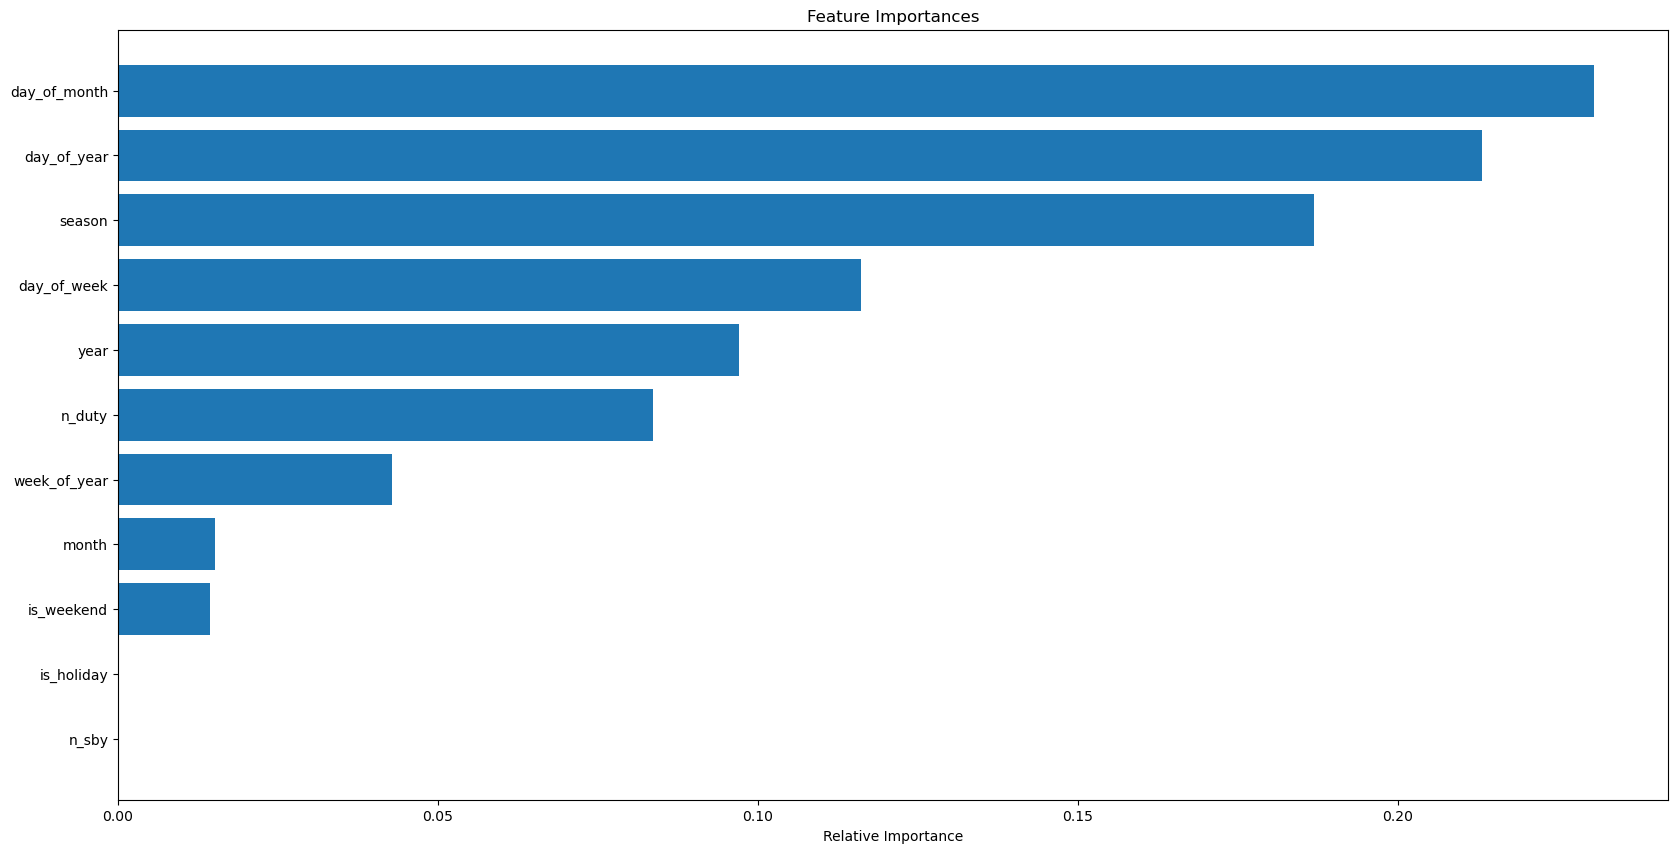

In [24]:
plt.figure(figsize=(20, 10))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()